In [ ]:
!pip install pycocotools --quiet

In [ ]:
!rm /content/annotations_trainval2017.zip*
!wget -q --show-progress http://images.cocodataset.org/annotations/annotations_trainval2017.zip

In [ ]:
!wget http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -q annotations_trainval2017.zip

In [ ]:
!unzip -q annotations_trainval2017.zip -d /content/
!ls /content/annotations/

In [ ]:
from pycocotools.coco import COCO

coco = COCO('annotations/instances_val2017.json')

cat_ids = coco.getCatIds(catNms=['bicycle'])
print("Kategori ID:", cat_ids)

img_ids = coco.getImgIds(catIds=cat_ids)
print(f"Bisiklet içeren foto sayısı: {len(img_ids)}")

loading annotations into memory...
Done (t=1.02s)
creating index...
index created!
Kategori ID: [2]
Bisiklet içeren foto sayısı: 149


In [ ]:
neg_cat_ids = coco.getCatIds(catNms=['cat', 'car', 'dog'])
print("Negatif kategori ID'leri:", neg_cat_ids)

neg_img_ids_all = []
for cid in neg_cat_ids:
    ids = coco.getImgIds(catIds=[cid])
    neg_img_ids_all.extend(ids)

neg_img_ids_all = list(set(neg_img_ids_all))
print(f"Negatif foto sayısı: {len(neg_img_ids_all)}")

Negatif kategori ID'leri: [3, 17, 18]
Negatif foto sayısı: 854


In [ ]:
bicycle_img_ids_set = set(img_ids)

neg_img_ids_clean = [i for i in neg_img_ids_all if i not in bicycle_img_ids_set]
#burada içinde bisiklet barındıran negatif  görüntüleri temziliyoruz.
print(f"Negatif foto sayısı: {len(neg_img_ids_clean)}")

Negatif foto sayısı: 794


In [ ]:
import random
random.seed(42)

N = 60

pos_sample = random.sample(img_ids, N)
neg_sample = random.sample(neg_img_ids_clean, N)

print(f"Pozitif örneklem: {len(pos_sample)}")
print(f"Negatif örneklem: {len(neg_sample)}")

Pozitif örneklem: 60
Negatif örneklem: 60


In [ ]:
import os
import cv2
import urllib.request

os.makedirs('data/pos', exist_ok=True)
os.makedirs('data/neg', exist_ok=True)

# Pozitif görüntüleri indirip kırpcaz burada
for img_id in pos_sample:
    img_info = coco.loadImgs(img_id)[0]
    img_url = img_info['coco_url']
    img_path = f"data/pos/{img_id}.jpg"

    try:
        urllib.request.urlretrieve(img_url, img_path)
    except Exception as e:
        print(f"Hata (indirme): {img_id} - {e}")
        continue

    img = cv2.imread(img_path)
    ann_ids = coco.getAnnIds(imgIds=img_id, catIds=cat_ids)
    anns = coco.loadAnns(ann_ids)

    for i, ann in enumerate(anns):
        x, y, w, h = [int(v) for v in ann['bbox']]
        crop = img[y:y+h, x:x+w]#sadece bisikletin olduğu dikdörtgen alanı kesip alıyoruz
        if crop.size > 0:
            cv2.imwrite(f"data/pos/{img_id}_{i}.jpg", crop)

    os.remove(img_path)  # orijinal dosyayı silip sadece kırpılmış parçaları tutuyoruz.

print(f"Toplam kırpılmış pozitif foto: {len(os.listdir('data/pos'))}")

Toplam kırpılmış pozitif foto: 134


In [ ]:
for img_id in neg_sample:
    img_info = coco.loadImgs(img_id)[0]
    img_url = img_info['coco_url']
    img_path = f"data/neg/{img_id}.jpg"

    try:
        urllib.request.urlretrieve(img_url, img_path)
    except Exception as e:
        print(f"Hata (indirme): {img_id} - {e}")

print(f"Toplam negatif foto: {len(os.listdir('data/neg'))}")

Toplam negatif foto: 60


In [ ]:
import urllib.request
import os

os.makedirs('data/neg', exist_ok=True)
# os.makedirs: klasör oluşturur
# exist_ok=True: klasör zaten varsa hata verme sessizce geç manasında
for img_id in neg_sample:
    img_info = coco.loadImgs(img_id)[0]
    # coco.loadImgs: verilen ID'ye ait görüntü bilgilerini (dosya adı, url, boyut) sözlük olarak döndürür

    img_url = img_info['coco_url']

    img_path = f"data/neg/{img_id}.jpg"

    try:
        urllib.request.urlretrieve(img_url, img_path)
        # urldeki dosyayı indirip img_path e kaydediyor
    except Exception as e:
        print(f"Hata: {img_id} - {e}")
        # indirme başarısız olursa o ID'yi atlayıp devam et demek

print(f"Toplam negatif dosya: {len(os.listdir('data/neg'))}")
# os.listdir: klasördeki dosyaları liste olarak döndürür len() ile sayıyoruz

Toplam negatif dosya: 60


In [ ]:
from skimage.feature import hog
from skimage import color
import cv2
import numpy as np

def goruntu_hog(img_path):
    img = cv2.imread(img_path)
    # cv2.imread: görüntüyü diskten okur numpy dizisi olarak döndürür

    img = cv2.resize(img, (64, 64))
    # tüm görüntüleri 64x64 piksel boyutuna getiriyoz hog için

    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    # hog için renkli görüntüyü gri tonlamaya çeviriyoz

    features = hog(img_gray, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    # pixels_per_cell=(8,8): her hücre 8x8 piksel
    # cells_per_block=(2,2): normalizasyon için 2x2 hücrelik bloklar kullan

    return features

In [ ]:
X = []  # özellik vektörleriiçin liste
y = []  # etiketleri için liste

for dosya in os.listdir('data/pos'):
    yol = f"data/pos/{dosya}"
    features = goruntu_hog(yol)
    X.append(features)
    y.append(1)
    # pozitif görüntüler → etiket 1

for dosya in os.listdir('data/neg'):
    yol = f"data/neg/{dosya}"
    features = goruntu_hog(yol)
    X.append(features)
    y.append(0)
    # negatif görüntüler → etiket 0

X = np.array(X)
y = np.array(y)
# listeleri numpy dizisine çevir — sklearn bunu bekliyor

print(f"X şekli: {X.shape}")
print(f"y şekli: {y.shape}")
# X.shape: (toplam_görüntü_sayısı, özellik_vektörü_uzunluğu) olmalı

X şekli: (194, 1764)
y şekli: (194,)


In [ ]:
from sklearn.model_selection import train_test_split

# önce %80 train, %20 geçici test olarak bölüyoz
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
    # random_state=42: bölmeyi sabitler her çalıştırmada aynı sonuç
)

# Sonra o %20'yi ikiye böl: %10 val, %10 test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    # %20'nin yarısı = toplam verinin %10'u
    random_state=42
)

print(f"Train: {len(X_train)}")
print(f"Val:   {len(X_val)}")
print(f"Test:  {len(X_test)}")

Train: 155
Val:   19
Test:  20


In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)
# Standardscaler her özelliği ortalama=0-standart sapma=1 olacak şekilde ölçüyor
# svm mesafeye dayalı çalıştığı için ölçekleme çok önemli
# fit_transform ortalama/std'yi train'den öğren ve uygula
# transform sadece uygula (val/test için train'in istatistiklerini kullan, kendi istatistiklerini değil)

svm = SVC(kernel='linear', C=0.1, probability=True, random_state=42)
# kernel='rbf':doğrusal olmayan sınırlar çizebilir (bisiklet şekilleri karmaşık)
# C=1.0: ne kadar katı sınır çizileceğini belirler (büyük C : daha katı)
# probability=True bisiklet olma olasılığı da hesaplayabilsin diye

svm.fit(X_train_scaled, y_train)
# modeli train verisiyle eğit

print(f"Train doğruluğu: {svm.score(X_train_scaled, y_train):.2f}")
print(f"Val doğruluğu:   {svm.score(X_val_scaled, y_val):.2f}")

Train doğruluğu: 1.00
Val doğruluğu:   0.89


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = svm.predict(X_test_scaled)


print(f"Test Accuracy (Doğruluk):{accuracy_score(y_test, y_pred):.2f}")
print(f"Test Precision (Hassasiyet):{precision_score(y_test, y_pred):.2f}")
print(f"Test Recall (Geri Çağırma):{recall_score(y_test, y_pred):.2f}")
print(f"Test F1 Skoru:{f1_score(y_test, y_pred):.2f}")
# accuracy:genel doğruluk oranı
# precision:bisiklet dediğimizin kaçı gerçekten bisiklet
# recall:gerçek bisikletlerin kaçını bulduk
# f1:precision ve recall'ın dengeli ortalaması

Test Accuracy (Doğruluk):0.85
Test Precision (Hassasiyet):0.93
Test Recall (Geri Çağırma):0.88
Test F1 Skoru:0.90


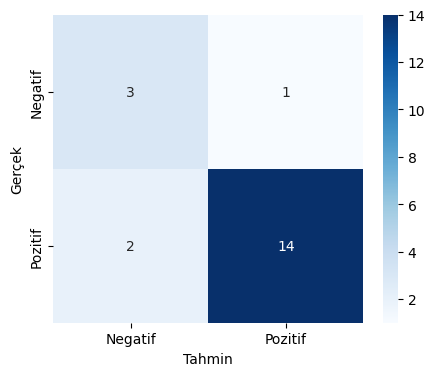

In [ ]:
cm = confusion_matrix(y_test, y_pred)
# cm: 2x2 matris
# [0,0] : doğru negatif (bisiklet yok,yok dedi)
# [0,1] : yanlış pozitif (bisiklet yok ama var dedi)
# [1,0] : yanlış negatif (bisiklet var ama yok dedi)
# [1,1] : doğru pozitif (bisiklet var, var dedi)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif', 'Pozitif'],
            yticklabels=['Negatif', 'Pozitif'])
# annot=True hücrelere sayıları yaz
# fmt='d' tam sayı formatı
plt.xlabel('Tahmin')
plt.ylabel('Gerçek')
plt.show()

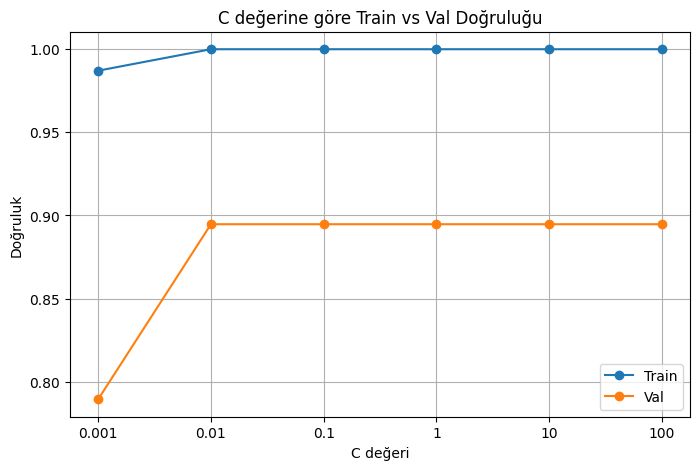

In [ ]:
C_degerler = [0.001, 0.01, 0.1, 1, 10, 100]
train_skorlar = []
val_skorlar = []

for c in C_degerler:
    model = SVC(kernel='linear', C=c, probability=True, random_state=42)
    model.fit(X_train_scaled, y_train)
    train_skorlar.append(model.score(X_train_scaled, y_train))
    val_skorlar.append(model.score(X_val_scaled, y_val))
    # her C değeri için train ve val doğruluğunu kaydediyoz

plt.figure(figsize=(8, 5))
plt.plot(range(len(C_degerler)), train_skorlar, label='Train', marker='o')
plt.plot(range(len(C_degerler)), val_skorlar, label='Val', marker='o')
plt.xticks(range(len(C_degerler)), [str(c) for c in C_degerler])
plt.xlabel('C değeri')
plt.ylabel('Doğruluk')
plt.title('C değerine göre Train vs Val Doğruluğu')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import os

neg_dosyalar = os.listdir('data/neg')
sahne_yolu = f"data/neg/{neg_dosyalar[0]}"
# neg klasöründeki ilk görüntüyü sahne olarak seç

sahne = cv2.imread(sahne_yolu)
print(f"Sahne boyutu: {sahne.shape}")
# shape: (yükseklik, genişlik, kanal_sayısı) — kanal_sayısı BGR için 3

Sahne boyutu: (480, 640, 3)


In [ ]:
def sliding_window(image, window_size, step_size):
    # window_size: pencerenin  boyutu
    # step_size: her adımda kaç piksel kayacağı

    for y in range(0, image.shape[0] - window_size[1], step_size):
        # image.shape[0]: görüntünün yüksekliği
        # yukarıdan aşağıya doğru ilerle
        for x in range(0, image.shape[1] - window_size[0], step_size):
            # image.shape[1]: görüntünün genişliği
            # soldan sağa doğru ilerle

            pencere = image[y:y+window_size[1], x:x+window_size[0]]
            # o konumdaki dikdörtgen bölgeyi kes

            yield (x, y, pencere)
            # yield: fonksiyonu durdurmadan her pencereyi sırayla döndürür
            # (x, y): pencerenin sol üst köşesinin koordinatları

In [ ]:
tespitler = []
# bisiklet tespit edilen pencerelerin koordinatlarını tutacak liste

pencere_boyutu = (64, 64)
adim = 16
# adim=16: her adımda 16 piksel kay
# küçük adım: daha hassas tarama ama daha yavaş

for (x, y, pencere) in sliding_window(sahne, pencere_boyutu, adim):
    pencere_gray = cv2.cvtColor(pencere, cv2.COLOR_BGR2GRAY)

    features = hog(pencere_gray, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    features = features.reshape(1, -1)
    # reshape(1, -1): svm tek örnek için (1, özellik_sayısı) şeklinde girdi bekler
    # -1: numpy'nin özellik sayısını otomatik hesapla demek

    features_scaled = scaler.transform(features)
    # train'de öğrendiğimiz ölçeklemeyi uygula

    tahmin = svm.predict(features_scaled)[0]
    olasilik = svm.predict_proba(features_scaled)[0][1]
    # predict: 0 veya 1 tahmini
    # predict_proba: her sınıf için olasılık, [1] bisiklet olasılığı

    if tahmin == 1 and olasilik > 0.8:
        tespitler.append((x, y, x+64, y+64, olasilik))
        # (x1, y1, x2, y2, olasilik) formatında kaydet
        # eşik 0.8: sadece yüksek güvenli tespitleri al

print(f"Tespit edilen pencere sayısı: {len(tespitler)}")

Tespit edilen pencere sayısı: 347


In [ ]:
def nms(tespitler, esik=0.3):
    # esik: iki pencerenin ne kadar üst üste binebileceği ,0.3 = %30'dan fazla binişim varsa birini at

    if len(tespitler) == 0:
        return []

    kutular = np.array([(x1, y1, x2, y2) for (x1, y1, x2, y2, _) in tespitler])
    olasiliklar = np.array([olas for (_, _, _, _, olas) in tespitler])

    x1 = kutular[:, 0]
    y1 = kutular[:, 1]
    x2 = kutular[:, 2]
    y2 = kutular[:, 3]

    alanlar = (x2 - x1) * (y2 - y1)
    # her pencerenin alanı

    siralama = olasiliklar.argsort()[::-1]
    # olasılığa göre büyükten küçüğe sıralamayı yapıyoz burada

    secilen = []

    while len(siralama) > 0:
        i = siralama[0]
        secilen.append(i)
        # en yüksek olasılıklıyı seç

        xx1 = np.maximum(x1[i], x1[siralama[1:]])
        yy1 = np.maximum(y1[i], y1[siralama[1:]])
        xx2 = np.minimum(x2[i], x2[siralama[1:]])
        yy2 = np.minimum(y2[i], y2[siralama[1:]])
        # seçilen pencere ile diğerlerinin kesişim koordinatları

        w = np.maximum(0, xx2 - xx1)
        h = np.maximum(0, yy2 - yy1)
        kesisim = w * h
        # kesişim alanı

        iou = kesisim / (alanlar[i] + alanlar[siralama[1:]] - kesisim)
        # Iou (Intersection over Union): kesişim / birleşim
        # ne kadar üst üste bindiklerini 0-1 arasında ölçer

        siralama = siralama[np.where(iou <= esik)[0] + 1]
        # eşikten fazla üst üste binenlerle devam etme

    return [tespitler[i] for i in secilen]

temiz_tespitler = nms(tespitler)
print(f"NMS sonrası tespit sayısı: {len(temiz_tespitler)}")

NMS sonrası tespit sayısı: 93


Sahne boyutu: (640, 428, 3)


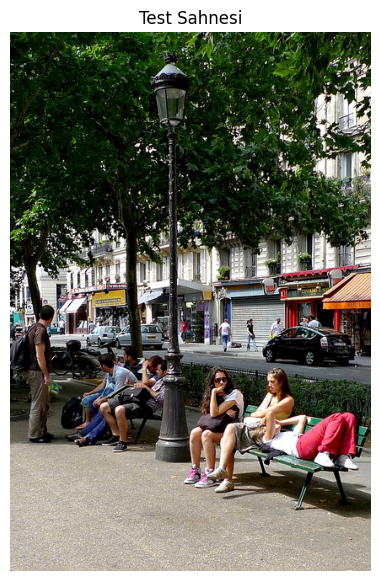

In [ ]:
# pos_sample listesindeki ilk görüntünün tam halini indir
img_info = coco.loadImgs(pos_sample[0])[0]
img_url = img_info['coco_url']

urllib.request.urlretrieve(img_url, 'sahne_test.jpg')
# tam sahneyi kırpmadan kaydet

sahne = cv2.imread('sahne_test.jpg')
print(f"Sahne boyutu: {sahne.shape}")

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(sahne, cv2.COLOR_BGR2RGB))
plt.title("Test Sahnesi")
plt.axis('off')
plt.show()

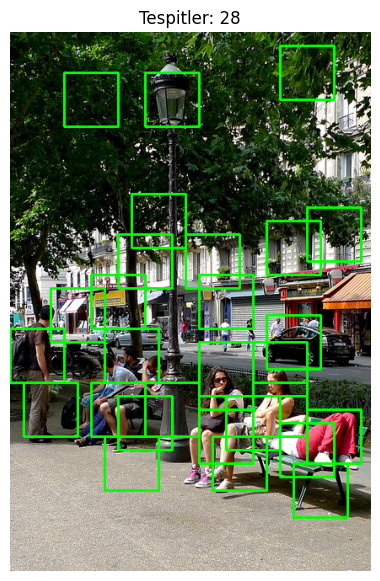

In [ ]:
tespitler = []
for (x, y, pencere) in sliding_window(sahne, (64, 64), 16):
    pencere_gray = cv2.cvtColor(pencere, cv2.COLOR_BGR2GRAY)
    features = hog(pencere_gray, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    features = scaler.transform(features.reshape(1, -1))
    tahmin = svm.predict(features)[0]
    olasilik = svm.predict_proba(features)[0][1]
    if tahmin == 1 and olasilik > 0.95:
        tespitler.append((x, y, x+64, y+64, olasilik))

temiz_tespitler = nms(tespitler)

sonuc = sahne.copy()
for (x1, y1, x2, y2, olas) in temiz_tespitler:
    cv2.rectangle(sonuc, (x1, y1), (x2, y2), (0, 255, 0), 2)

plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title(f"Tespitler: {len(temiz_tespitler)}")
plt.axis('off')
plt.show()